1. FIND-S Algorithm

Training Data:


,Sky,AirTemp,Humidity,Wind,EnjoySport
0,Sunny,Warm,Normal,Strong,Yes
1,Sunny,Warm,High,Strong,Yes
2,Rainy,Cold,High,Strong,No
3,Sunny,Warm,High,Weak,Yes



Most Specific Hypothesis:
['Sunny', 'Warm', '?', '?']


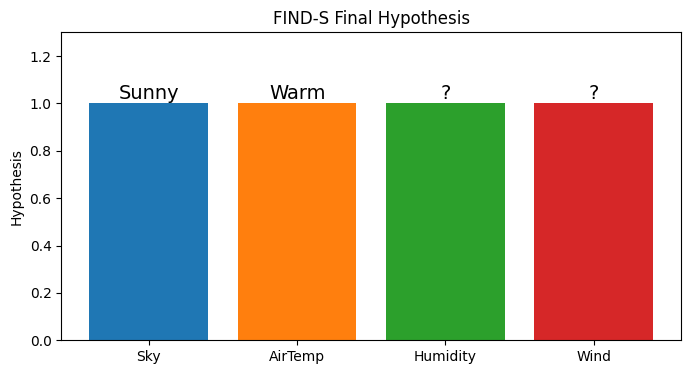

In [2]:
# EXPERIMENT 1: FIND-S ALGORITHM

import pandas as pd
import matplotlib.pyplot as plt

data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Weak'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

print("Training Data:")
display(df)

# FIND-S
hypothesis = ['0'] * 4

for _, row in df.iterrows():
    if row['EnjoySport'] == 'Yes':
        if hypothesis == ['0'] * 4:
            hypothesis = list(row[:4])
        else:
            for i in range(4):
                if hypothesis[i] != row.iloc[i]:
                    hypothesis[i] = '?'

print("\nMost Specific Hypothesis:")
print(hypothesis)

# Visualization
plt.figure(figsize=(8, 4))
for i, value in enumerate(hypothesis):
    plt.bar(i, 1)
    plt.text(i, 1.02, value, ha='center', fontsize=14)

plt.xticks(range(4), ['Sky', 'AirTemp', 'Humidity', 'Wind'])
plt.ylabel("Hypothesis")
plt.title("FIND-S Final Hypothesis")
plt.ylim(0, 1.3)
plt.show()

2. Candidate-Elimination Algorithm

Specific Boundary S:
['Sunny', 'Warm', '?', '?']

General Boundary G:
['Sunny', '?', '?', '?']
['?', 'Warm', '?', '?']
['?', '?', '?', '?']


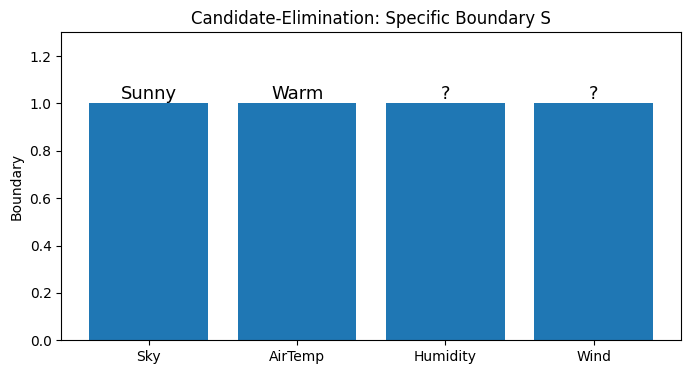

In [4]:
# EXPERIMENT 2: CANDIDATE-ELIMINATION

import pandas as pd
import matplotlib.pyplot as plt

data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Weak'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

attributes = list(df.columns[:-1])

S = ['0'] * len(attributes)
G = [['?'] * len(attributes)]

for _, row in df.iterrows():
    example = list(row[:-1])
    target = row.iloc[-1]

    if target == 'Yes':
        for i in range(len(S)):
            if S[i] == '0':
                S[i] = example[i]
            elif S[i] != example[i]:
                S[i] = '?'

        G = [
            g for g in G
            if all(g[i] == '?' or g[i] == example[i] for i in range(len(attributes)))
        ]

    else:
        new_G = []
        for g in G:
            for i in range(len(attributes)):
                if g[i] == '?' and S[i] != example[i]:
                    new_g = g.copy()
                    new_g[i] = S[i]
                    new_G.append(new_g)
        if new_G:
            G = new_G

print("Specific Boundary S:")
print(S)

print("\nGeneral Boundary G:")
for g in G:
    print(g)

# Visualization
plt.figure(figsize=(8, 4))
plt.bar(attributes, [1] * len(attributes))

for i, value in enumerate(S):
    plt.text(i, 1.02, value, ha='center', fontsize=13)

plt.title("Candidate-Elimination: Specific Boundary S")
plt.ylabel("Boundary")
plt.ylim(0, 1.3)
plt.show()

3. ID3 Decision Tree

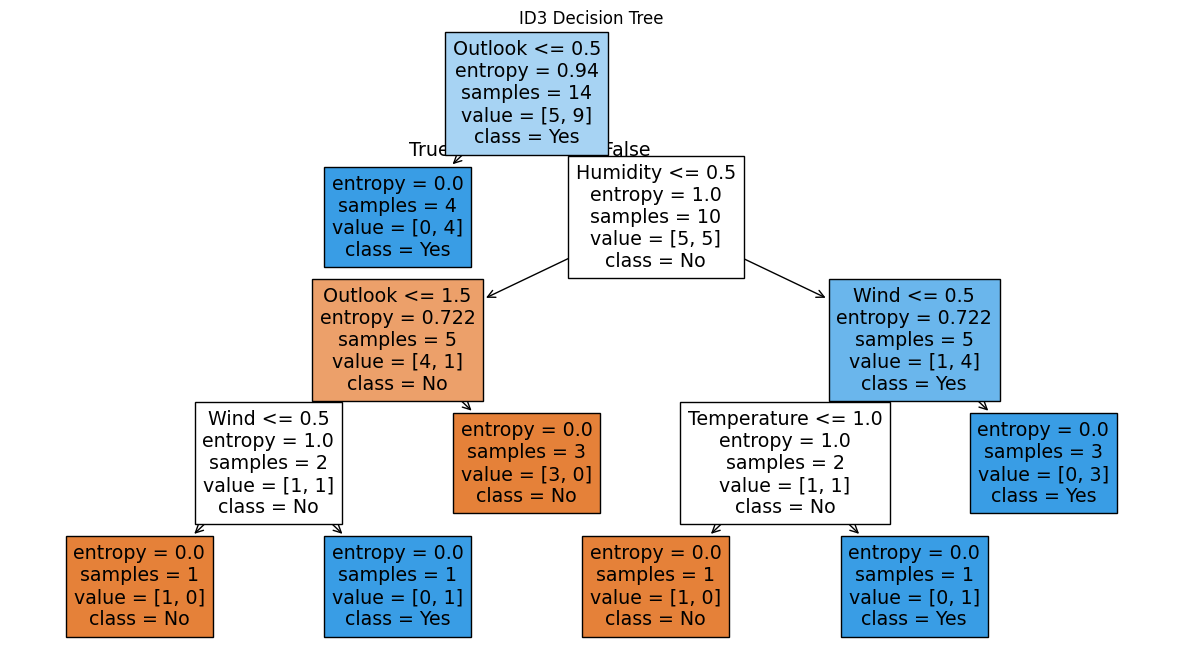

New Sample: ['Sunny', 'Cool', 'High', 'Strong']
Prediction: No


In [8]:
# EXPERIMENT 3: ID3 DECISION TREE

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain', 'Rain',
                'Overcast', 'Sunny', 'Sunny', 'Rain', 'Sunny', 'Overcast',
                'Overcast', 'Rain'],
    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool',
                    'Cool', 'Mild', 'Cool', 'Mild', 'Mild', 'Mild',
                    'Hot', 'Mild'],
    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal',
                 'Normal', 'High', 'Normal', 'Normal', 'Normal', 'High',
                 'Normal', 'High'],
    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong',
             'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong',
             'Weak', 'Strong'],
    'Play': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes',
             'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No']
}

df = pd.DataFrame(data)

encoders = {}

for column in df.columns:
    le = LabelEncoder()
    df[column] = le.fit_transform(df[column])
    encoders[column] = le

X = df.drop('Play', axis=1)
y = df['Play']

model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

model.fit(X, y)

plt.figure(figsize=(15, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['No', 'Yes'],
    filled=True
)

plt.title("ID3 Decision Tree")
plt.show()

# New sample
sample_original = ['Sunny', 'Cool', 'High', 'Strong']

sample_df = pd.DataFrame([[
    encoders['Outlook'].transform(['Sunny'])[0],
    encoders['Temperature'].transform(['Cool'])[0],
    encoders['Humidity'].transform(['High'])[0],
    encoders['Wind'].transform(['Strong'])[0]
]], columns=X.columns)

prediction = model.predict(sample_df)

print("New Sample:", sample_original)
print("Prediction:", encoders['Play'].inverse_transform(prediction)[0])

4. ANN Using Backpropagation

Actual: [0 1 1 0]
Predicted: [0 1 1 0]
Training Accuracy: 100.0 %


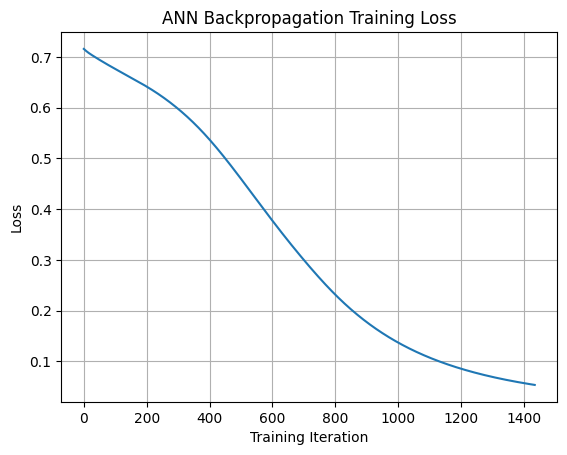

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 1, 1, 0])

model = MLPClassifier(
    hidden_layer_sizes=(8,),
    activation="tanh",
    solver="adam",
    max_iter=3000,
    random_state=42
)

model.fit(X, y)
pred = model.predict(X)

print("Actual:", y)
print("Predicted:", pred)
print("Training Accuracy:", accuracy_score(y, pred) * 100, "%")

plt.plot(model.loss_curve_)
plt.xlabel("Training Iteration")
plt.ylabel("Loss")
plt.title("ANN Backpropagation Training Loss")
plt.grid()
plt.show()

5. K-Nearest Neighbours (KNN)

Accuracy: 93.33333333333333 %


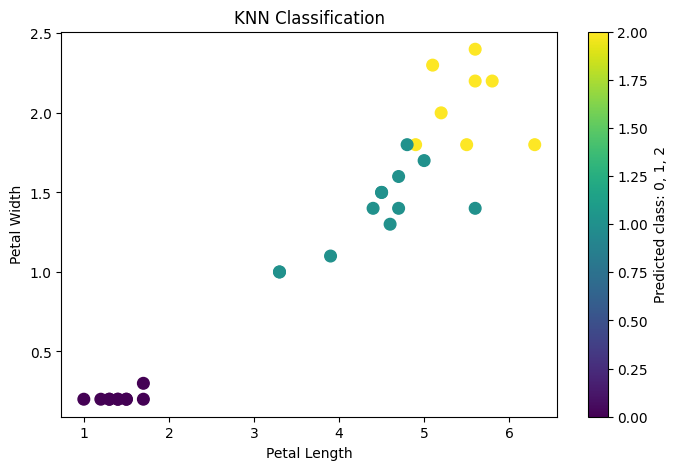

In [11]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred) * 100, "%")

plt.figure(figsize=(8, 5))
plt.scatter(X_test[:, 2], X_test[:, 3], c=pred, cmap="viridis", s=70)
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("KNN Classification")
plt.colorbar(label="Predicted class: 0, 1, 2")
plt.show()

6. Naïve Bayes with Confusion Matrix

Accuracy: 96.66666666666667 %


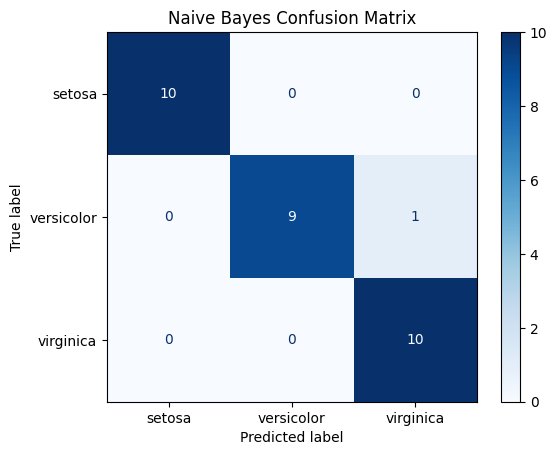

In [13]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = GaussianNB()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred) * 100, "%")

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=iris.target_names, cmap="Blues"
)
plt.title("Naive Bayes Confusion Matrix")
plt.show()

7. Logistic Regression

Accuracy: 93.33333333333333 %


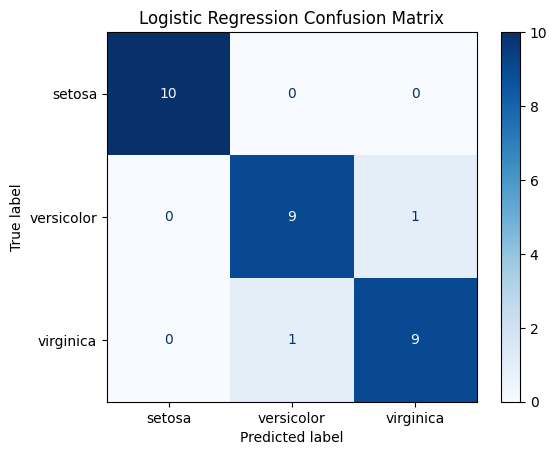

In [15]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

iris = load_iris()
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred) * 100, "%")

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=iris.target_names, cmap="Blues"
)
plt.title("Logistic Regression Confusion Matrix")
plt.show()

8. Linear Regression

Slope: 2.0
Intercept: -0.20000000000000018
Prediction for X=6: 11.8


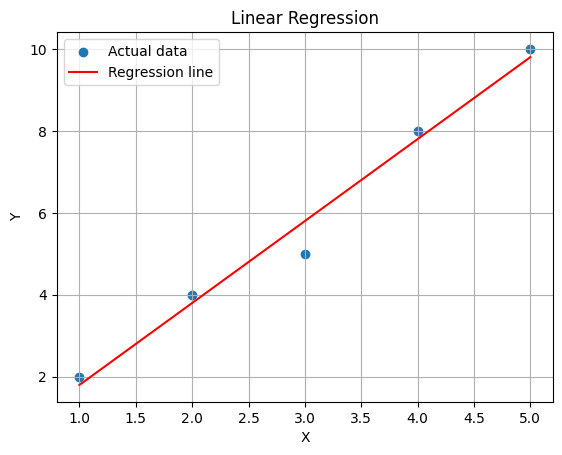

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

X = np.array([1, 2, 3, 4, 5]).reshape(-1, 1)
y = np.array([2, 4, 5, 8, 10])

model = LinearRegression()
model.fit(X, y)
pred = model.predict(X)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)
print("Prediction for X=6:", model.predict([[6]])[0])

plt.scatter(X.ravel(), y, label="Actual data")
plt.plot(X.ravel(), pred, color="red", label="Regression line")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Linear Regression")
plt.legend()
plt.grid()
plt.show()

9. Linear vs Polynomial Regression

Linear MSE: 35.14434523809524
Polynomial MSE: 0.1078869047619041


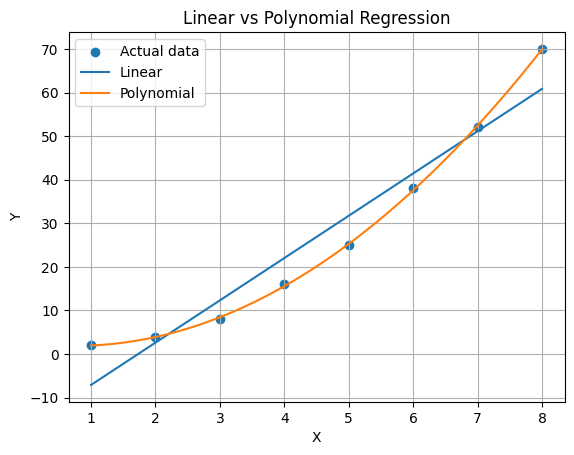

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error

X = np.array([1, 2, 3, 4, 5, 6, 7, 8]).reshape(-1, 1)
y = np.array([2, 4, 8, 16, 25, 38, 52, 70])

linear = LinearRegression()
linear.fit(X, y)
linear_pred = linear.predict(X)

poly_features = PolynomialFeatures(degree=2)
X_poly = poly_features.fit_transform(X)

polynomial = LinearRegression()
polynomial.fit(X_poly, y)
poly_pred = polynomial.predict(X_poly)

print("Linear MSE:", mean_squared_error(y, linear_pred))
print("Polynomial MSE:", mean_squared_error(y, poly_pred))

X_smooth = np.linspace(1, 8, 200).reshape(-1, 1)

plt.scatter(X.ravel(), y, label="Actual data")
plt.plot(X_smooth.ravel(), linear.predict(X_smooth), label="Linear")
plt.plot(
    X_smooth.ravel(),
    polynomial.predict(poly_features.transform(X_smooth)),
    label="Polynomial"
)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid()
plt.show()

10. Expectation-Maximization (EM)

Cluster Centers:
[[1.9926269  1.97692238]
 [7.02941708 6.99066054]]


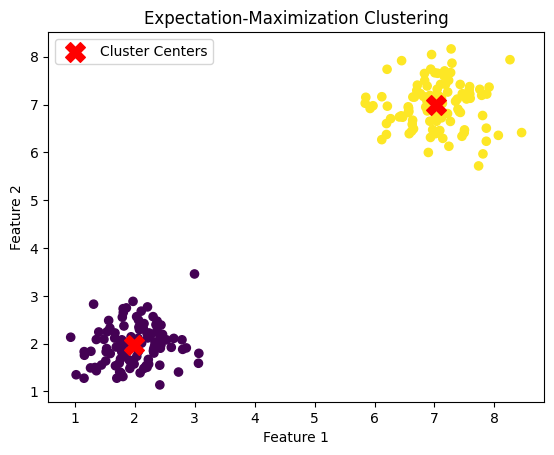

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

rng = np.random.default_rng(42)

group1 = rng.normal(2, 0.5, size=(100, 2))
group2 = rng.normal(7, 0.5, size=(100, 2))
X = np.vstack([group1, group2])

model = GaussianMixture(n_components=2, random_state=42)
model.fit(X)

labels = model.predict(X)

print("Cluster Centers:")
print(model.means_)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=35)
plt.scatter(
    model.means_[:, 0], model.means_[:, 1],
    marker="X", s=200, color="red", label="Cluster Centers"
)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Expectation-Maximization Clustering")
plt.legend()
plt.show()